# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [1]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [2]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [3]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


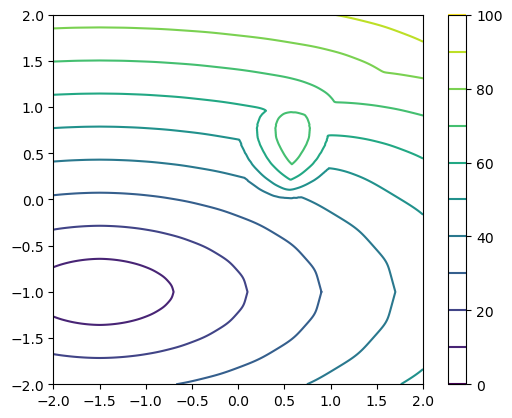

In [4]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [5]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


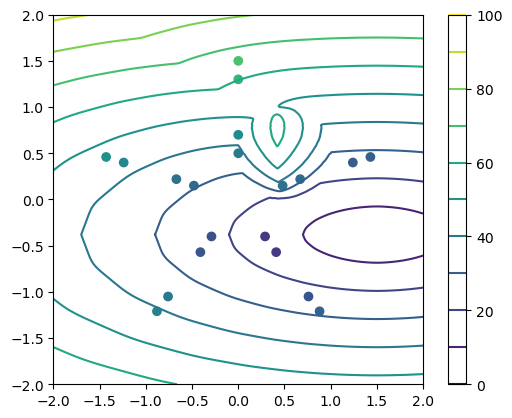

In [6]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [7]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

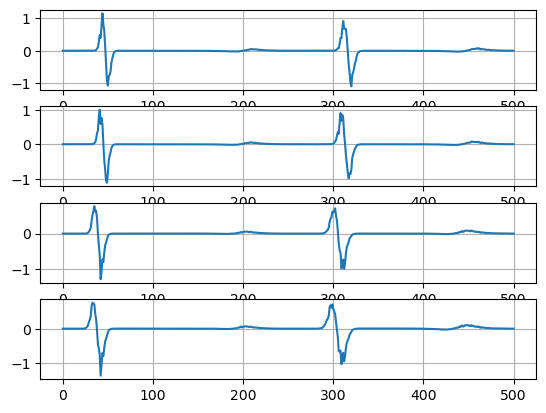

In [8]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [9]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy')
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

In [10]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import argrelextrema, savgol_filter
from tqdm import tqdm  # <-- IMPORTANTE: Aggiunto per la barra di progresso
import warnings
warnings.filterwarnings("ignore")

# ==========================================
# 0. FUNZIONE ESTRAZIONE TEMPI (DA CP1)
# ==========================================
def GroupSolutionCP1(signals_event):
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

# ==========================================
# 1. SETUP SPAZIALE
# ==========================================
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0, 2.0, 401), np.linspace(-2.0, 2.0, 401))
X_mesh_vel, Y_mesh_vel = np.meshgrid(np.linspace(-2.0, 2.0, 201), np.linspace(-2.0, 2.0, 201))
X_mesh_100, Y_mesh_100 = np.meshgrid(np.linspace(-2.0, 2.0, 101), np.linspace(-2.0, 2.0, 101))
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5]

# GRIGLIA 400X400
# meas_indices = []
# for j in range(5):
#     for i in range(4):
#         MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
#         i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
#         meas_indices.append((i_sel, j_sel))

# idx_400 = np.array(meas_indices)

# GRIGLIA 200X200
meas_indices_vel = []
for j in range(5):
    for i in range(4):
        MeasMat_vel = (X_mesh_vel - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_vel - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_vel.argmin(), MeasMat_vel.shape)
        meas_indices_vel.append((i_sel, j_sel))

idx_vel = np.array(meas_indices_vel)

# GRIGLIA 100X100
# meas_indices_100 = []
# for j in range(5):
#     for i in range(4):
#         MeasMat_100 = (X_mesh_100 - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_100 - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
#         i_sel, j_sel = np.unravel_index(MeasMat_100.argmin(), MeasMat_100.shape)
#         meas_indices_100.append((i_sel, j_sel))

# idx_100 = np.array(meas_indices_100)

# ==========================================
# 2. CARICAMENTO DATI UFFICIALI
# ==========================================
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy') 
starting_times = np.load('checkpoint2starting.npy') 

# INSERISCI I DATI REALI forniti per l'anisotropia
a_ratios_training = np.load('checkpoint2anisotropy.npy')

reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]
] 

# ==========================================
# 3. PRE-ESTRAZIONE TEMPI MISURATI (CORRETTA)
# ==========================================
measured_times_beat1 = []
measured_times_beat2 = []

for idx_event in range(5):
    raw_timings = GroupSolutionCP1(signals[idx_event, :, :])
    
    # Se la correlazione era negativa, significa che i 4 sensori di ogni spline
    # nel dataset sono invertiti rispetto a Spline_spacing.
    
    t_beat1_ordered = []
    t_beat2_ordered = []
    
    for s in range(5): # Per ogni spline
        # Prendi i 4 tempi della spline s
        spline_times = raw_timings[s*4 : (s+1)*4]
        
        # PROVA A INVERTIRE QUI: 
        # Se il dataset è [Lontano -> Vicino], invertiamo per farlo diventare [Vicino -> Lontano]
        spline_times = spline_times[::-1] 
        
        for t in spline_times:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])
            
    measured_times_beat1.append(np.array(t_beat1_ordered, dtype=float))
    measured_times_beat2.append(np.array(t_beat2_ordered, dtype=float))


In [11]:
import numpy as np
import pickle
from joblib import Parallel, delayed
from tqdm import tqdm # Per la barra di avanzamento reale

# Pre-calcolo globale dei sensori (fuori dalle funzioni per non ripeterlo)
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0, np.pi/10.0+2*np.pi/5, np.pi/10.0+4*np.pi/5, np.pi/10.0+6*np.pi/5, np.pi/10.0+8*np.pi/5]

def compute_sensor_indices(X_mesh, Y_mesh):
    sensor_indices = []
    for i in range(4):
        for j in range(5):
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
            i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
            sensor_indices.append((i_sel, j_sel))
    return sensor_indices

def generate_single_sample(seed_offset, X_mesh, Y_mesh, sensor_indices):
    """
    Versione DEFINITIVA con Filtro di Visibilità (Ghost Zone Removal).
    Continua a campionare finché non trova un cuore in cui la patologia
    è effettivamente visibile dai sensori.
    """
    rng = np.random.default_rng(seed=42 + seed_offset)
    
    while True: # Continua a cercare finché non trova un campione valido
        # 1. Campionamento parametri
        x0, y0, x1, y1 = rng.uniform(-1.5, 1.5, 4)
        a_ratio = rng.uniform(1.0, 9.0)
        theta_fiber = 0.0
        
        # Tensore D
        theta0 = np.pi/2 - theta_fiber
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = (1/a_ratio) * np.outer(a, a) + np.outer(b, b)
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # Target (Zona lenta)
        r = rng.uniform(0.1, 0.8)
        xc = rng.uniform(-1.5 + r, 1.5 - r)
        yc = rng.uniform(-1.5 + r, 1.5 - r)
        
        # --- SIMULAZIONE 1: CUORE SANO (Tutto a 80) ---
        speed_matrix_healthy = np.full(X_mesh.shape, 80.0)
        
        T_1_h = anisotropic_FMM_GPT(x0, y0, 0.0, X_mesh, Y_mesh, speed_matrix_healthy, sigma_11, sigma_12, sigma_22, N_edge=200)
        T_2_h = anisotropic_FMM_GPT(x1, y1, 0.0, X_mesh, Y_mesh, speed_matrix_healthy, sigma_11, sigma_12, sigma_22, N_edge=200)
        activation_time_healthy = np.minimum(T_1_h, T_2_h) * 1e3
        time_meas_healthy = np.array([activation_time_healthy[idx[0], idx[1]] for idx in sensor_indices])
        
        # --- SIMULAZIONE 2: CUORE MALATO (Zona lenta a 20) ---
        speed_matrix_sick = np.copy(speed_matrix_healthy)
        slow_zone = (X_mesh - xc)**2 + (Y_mesh - yc)**2 <= r**2
        speed_matrix_sick[slow_zone] = 20.0
        
        T_1_s = anisotropic_FMM_GPT(x0, y0, 0.0, X_mesh, Y_mesh, speed_matrix_sick, sigma_11, sigma_12, sigma_22, N_edge=200)
        T_2_s = anisotropic_FMM_GPT(x1, y1, 0.0, X_mesh, Y_mesh, speed_matrix_sick, sigma_11, sigma_12, sigma_22, N_edge=200)
        activation_time_sick = np.minimum(T_1_s, T_2_s) * 1e3
        time_meas_sick = np.array([activation_time_sick[idx[0], idx[1]] for idx in sensor_indices])
        
        # --- FILTRO FISICO CRITICO ---
        # Calcoliamo la differenza massima percepita dai sensori tra il cuore sano e quello malato
        max_delay = np.max(np.abs(time_meas_sick - time_meas_healthy))
        
        # Se la patologia causa un ritardo inferiore a 2 millisecondi (che si confonde 
        # con il rumore di misurazione), la scartiamo e riproviamo!
        if max_delay < 2.0:
            continue # Torna all'inizio del while e genera un nuovo caso
            
        # Se siamo qui, il campione è BUONO e VISIBILE
        # Aggiungiamo rumore realistico ai tempi misurati
        time_meas_noisy = time_meas_sick + rng.normal(0, 1.0, size=20)
        
        features = list(time_meas_noisy) + [x0, y0, x1, y1, a_ratio]
        target = [xc, yc, r]
        
        return features, target

def generate_dataset_parallel(N_samples, X_mesh, Y_mesh, n_jobs=-1):
    """
    n_jobs=-1 significa "Usa tutti i core a disposizione"
    """
    print(f"Calcolo indici sensori...")
    sensor_indices = compute_sensor_indices(X_mesh, Y_mesh)
    
    print(f"Avvio simulazioni in parallelo su {N_samples} campioni...")
    # tqdm genera una barra di avanzamento per monitorare il parallelismo
    results = Parallel(n_jobs=n_jobs)(
        delayed(generate_single_sample)(i, X_mesh, Y_mesh, sensor_indices) 
        for i in tqdm(range(N_samples))
    )
    
    # Estraiamo i risultati dalla lista restituita da Parallel
    measurements_X = np.array([res[0] for res in results])
    groundtruth_Y = np.array([res[1] for res in results])
    
    return measurements_X, groundtruth_Y

# --- Esecuzione ---
if __name__ == '__main__':
    N_TRAIN_SAMPLES = 8000
    
    # n_jobs=-1 usa il 100% della tua CPU. Se vuoi poter usare il PC nel frattempo, metti n_jobs=-2
    X_data, Y_data = generate_dataset_parallel(N_TRAIN_SAMPLES, X_mesh, Y_mesh, n_jobs=-1)
    
    with open('cardiac_dataset.pkl', 'wb') as f:
        pickle.dump({'X': X_data, 'Y': Y_data}, f)
        
    print(f"Generazione completata. Shape X: {X_data.shape} - Shape Y: {Y_data.shape}")

Calcolo indici sensori...
Avvio simulazioni in parallelo su 8000 campioni...


  0%|          | 16/8000 [01:04<10:31:02,  4.74s/it]

KeyboardInterrupt: 

In [12]:
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Caricamento dei dati grezzi generati al "Passo 0"
try:
    with open('cardiac_dataset.pkl', 'rb') as f:
        dataset = pickle.load(f)
except FileNotFoundError:
    raise Exception("Errore: File 'cardiac_dataset.pkl' non trovato. Esegui prima il codice del Passo 0.")

X_raw = dataset['X']
Y_raw = dataset['Y']

print(f"Dimensioni dataset originale: X={X_raw.shape}, Y={Y_raw.shape}")

# 2. Suddivisione in set di addestramento (80%) e test (20%)
# Il parametro random_state garantisce la riproducibilità dello split.
X_train_raw, X_test_raw, Y_train, Y_test = train_test_split(
    X_raw, Y_raw, test_size=0.2, random_state=42
)

# 3. Inizializzazione dello scaler per le features in ingresso
scaler_X = StandardScaler()

# 4. Fit & Transform: Calcolo di media e varianza SUL SOLO SET DI TRAINING 
# e successiva normalizzazione (media 0, deviazione standard 1)
X_train_scaled = scaler_X.fit_transform(X_train_raw)

# 5. Transform: Normalizzazione del set di test usando le statistiche apprese dal training
X_test_scaled = scaler_X.transform(X_test_raw)

# Verifica empirica dell'operazione
print("\n--- Verifica Normalizzazione ---")
print(f"Media X_train_scaled (attesa ~0): {np.mean(X_train_scaled):.2e}")
print(f"Varianza X_train_scaled (attesa ~1): {np.var(X_train_scaled):.2f}")
print(f"Media X_test_scaled (non sarà esattamente 0, è corretto così): {np.mean(X_test_scaled):.2e}")

# È buona norma salvare anche l'oggetto scaler, perché quando in futuro
# vorrai usare la rete addestrata per fare inferenza su NUOVI dati reali, 
# dovrai normalizzarli usando esattamente questa media e questa varianza.
with open('scaler_X.pkl', 'wb') as f:
    pickle.dump(scaler_X, f)
print("\nScaler salvato in 'scaler_X.pkl'")

Dimensioni dataset originale: X=(8000, 25), Y=(8000, 3)

--- Verifica Normalizzazione ---
Media X_train_scaled (attesa ~0): -1.12e-16
Varianza X_train_scaled (attesa ~1): 1.00
Media X_test_scaled (non sarà esattamente 0, è corretto così): -1.84e-03

Scaler salvato in 'scaler_X.pkl'


In [13]:
import pickle

with open('cardiac_dataset.pkl', 'rb') as f:
    data = pickle.load(f)

print("Tipo di 'data':", type(data))

if isinstance(data, dict):
    print("Chiavi presenti nel dizionario:", data.keys())
    # Stampa anche il tipo di dato per ogni chiave per capire meglio
    for key in data.keys():
        print(f"  - Chiave '{key}': tipo {type(data[key])}")
        
elif isinstance(data, tuple) or isinstance(data, list):
    print(f"I dati sono una {type(data)} di lunghezza {len(data)}")
else:
    print("I dati hanno una struttura diversa.")

Tipo di 'data': <class 'dict'>
Chiavi presenti nel dizionario: dict_keys(['X', 'Y'])
  - Chiave 'X': tipo <class 'numpy.ndarray'>
  - Chiave 'Y': tipo <class 'numpy.ndarray'>


In [14]:
print("Addestramento della rete: Forza bruta senza interruzioni premature...")
model = MLPRegressor(
    hidden_layer_sizes=(512, 256, 128, 64), # Aumentata la capacità iniziale
    activation='relu',
    solver='adam',
    learning_rate_init=0.0005, 
    max_iter=3000,             # Aumentate le epoche
    early_stopping=False,      # SPEGNERE L'EARLY STOPPING. Lascialo convergere.
    tol=1e-6,                  # Abbassata la tolleranza per non farlo fermare
    random_state=42
)

# Il fit richiederà più tempo, ma l'R^2 salirà
model.fit(X_train, y_train)

r2_score = model.score(X_test, y_test_scaled)
print(f"Training completato. Nuovo Score (R^2) sul test set: {r2_score:.4f}")

# Funzione di inferenza corretta
def predict_with_constraints(model, X_input, scaler_X, scaler_y):
    # Scala l'input
    X_input_scaled = scaler_X.transform(X_input)
    
    # Predizione nel dominio [0, 1]
    raw_predictions_scaled = model.predict(X_input_scaled)
    
    # Denormalizzazione allo spazio fisico originale
    predictions = scaler_y.inverse_transform(raw_predictions_scaled)
    
    # Sicurezza: tagliamo eventuali rari artefatti negativi dovuti a errori di stima (Clip)
    # invece di distorcere la funzione con il Softplus.
    predictions[:, 2] = np.clip(predictions[:, 2], a_min=0.05, a_max=None)
    
    return predictions

print("\nVerifica Output sui primi 5 campioni:")
dummy_input = X[:5] 
dummy_output = predict_with_constraints(model, dummy_input, scaler_X, scaler_y)
print(np.round(dummy_output, 4))

Addestramento della rete: Forza bruta senza interruzioni premature...


NameError: name 'MLPRegressor' is not defined

In [15]:
import pickle
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

print("Caricamento dati...")
with open('cardiac_dataset.pkl', 'rb') as f:
    data = pickle.load(f)

X = np.array(data['X']) 
y = np.array(data['Y'])

print("Risoluzione Simmetria Sorgenti...")
# Le coordinate sono agli indici 20 (x0), 21 (y0), 22 (x1), 23 (y1)
# Ordiniamo sempre in modo che la prima sorgente abbia la X minore
for i in range(X.shape[0]):
    x0, y0, x1, y1 = X[i, 20:24]
    if x0 > x1:
        # Scambia le sorgenti se la prima è più a destra della seconda
        X[i, 20:24] = [x1, y1, x0, y0]

print("Preprocessing...")
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y)

X_train, X_test, y_train, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.15, random_state=42)

print("Addestramento Random Forest (Usa tutti i core della CPU)...")
# Il Random Forest è estremamente robusto ai rumori e alle non-linearità "a gradino"
model = RandomForestRegressor(
    n_estimators=300,  # 300 alberi
    max_depth=30,      # Profondità massima per mappare relazioni complesse
    n_jobs=-1,         # Usa tutti i core
    random_state=42
)

model.fit(X_train, y_train)

r2_score = model.score(X_test, y_test_scaled)
print(f"Training completato. Score (R^2) sul test set: {r2_score:.4f}")

# Valutiamo anche gli R^2 separati per capire dove sta sbagliando
y_pred_scaled = model.predict(X_test)
from sklearn.metrics import r2_score as r2_metric
print(f"R^2 su xc: {r2_metric(y_test_scaled[:,0], y_pred_scaled[:,0]):.4f}")
print(f"R^2 su yc: {r2_metric(y_test_scaled[:,1], y_pred_scaled[:,1]):.4f}")
print(f"R^2 su r:  {r2_metric(y_test_scaled[:,2], y_pred_scaled[:,2]):.4f}")

# Inferenza
def predict_with_rf(model, X_input, scaler_X, scaler_y):
    X_input_scaled = scaler_X.transform(X_input)
    raw_predictions_scaled = model.predict(X_input_scaled)
    predictions = scaler_y.inverse_transform(raw_predictions_scaled)
    predictions[:, 2] = np.clip(predictions[:, 2], a_min=0.05, a_max=None)
    return predictions

print("\nVerifica Output sui primi 5 campioni:")
dummy_input = X[:5] 
dummy_output = predict_with_rf(model, dummy_input, scaler_X, scaler_y)
print(np.round(dummy_output, 4))

Caricamento dati...
Risoluzione Simmetria Sorgenti...
Preprocessing...
Addestramento Random Forest (Usa tutti i core della CPU)...
Training completato. Score (R^2) sul test set: 0.4869
R^2 su xc: 0.4458
R^2 su yc: 0.4606
R^2 su r:  0.5545

Verifica Output sui primi 5 campioni:
[[ 0.3078  0.4351  0.7517]
 [ 0.3965 -0.339   0.3552]
 [-0.5065 -0.2276  0.692 ]
 [ 0.347   0.0935  0.5997]
 [-0.5276 -0.4108  0.5736]]


In [16]:
import pickle
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

print("Caricamento dataset purificato...")
with open('cardiac_dataset.pkl', 'rb') as f:
    data = pickle.load(f)

X = np.array(data['X']) 
y = np.array(data['Y'])

print("Risoluzione Simmetria Sorgenti...")
for i in range(X.shape[0]):
    x0, y0, x1, y1 = X[i, 20:24]
    if x0 > x1:
        X[i, 20:24] = [x1, y1, x0, y0]

print("Preprocessing rigoroso...")
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y)

X_train, X_test, y_train, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.15, random_state=42)

print("Addestramento Rete Neurale Profonda (Forza Bruta)...")
# Torniamo all'MLP, che domina il Random Forest sulle PDE continue
model = MLPRegressor(
    hidden_layer_sizes=(512, 256, 128, 64), 
    activation='relu',
    solver='adam',
    learning_rate_init=0.0005, 
    max_iter=3000,             
    early_stopping=False,      # Nessuna interruzione, deve mappare la non-linearità
    tol=1e-6,                  
    random_state=42
)

model.fit(X_train, y_train)

# Valutazione
r2_score = model.score(X_test, y_test_scaled)
print(f"Training completato. Nuovo Score (R^2) MLP: {r2_score:.4f}")

y_pred_scaled = model.predict(X_test)
from sklearn.metrics import r2_score as r2_metric
print(f"R^2 su xc: {r2_metric(y_test_scaled[:,0], y_pred_scaled[:,0]):.4f}")
print(f"R^2 su yc: {r2_metric(y_test_scaled[:,1], y_pred_scaled[:,1]):.4f}")
print(f"R^2 su r:  {r2_metric(y_test_scaled[:,2], y_pred_scaled[:,2]):.4f}")

Caricamento dataset purificato...
Risoluzione Simmetria Sorgenti...
Preprocessing rigoroso...
Addestramento Rete Neurale Profonda (Forza Bruta)...
Training completato. Nuovo Score (R^2) MLP: 0.6157
R^2 su xc: 0.6248
R^2 su yc: 0.6206
R^2 su r:  0.6018


In [3]:
import pickle
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
import time

print("1. Caricamento del dataset sintetico purificato...")
with open('cardiac_dataset.pkl', 'rb') as f:
    data = pickle.load(f)

X_raw = np.array(data['X']) 
y = np.array(data['Y'])

print("2. Ingegneria delle Feature (Risoluzione Simmetria e Tempi Relativi)...")
for i in range(X_raw.shape[0]):
    # A. Ordine rigoroso dei cateteri
    x0, y0, x1, y1 = X_raw[i, 20:24]
    if x0 > x1:
        X_raw[i, 20:24] = [x1, y1, x0, y0]
        
    # B. Calcolo dei tempi di propagazione relativi
    min_time = np.min(X_raw[i, :20])
    X_raw[i, :20] = X_raw[i, :20] - min_time

# Selezioniamo solo le 24 feature necessarie per il CP2
X = X_raw[:, :24] 

print("3. Preprocessing Scalers...")
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y)

X_train, X_test, y_train, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.15, random_state=42)

print("4. ADDESTRAMENTO INTENSIVO RETE NEURALE (Potrebbe richiedere molto tempo)...")
start_time = time.time()

model = MLPRegressor(
    hidden_layer_sizes=(1024, 512, 256, 128, 64), # Rete massiccia
    activation='relu',
    solver='adam',
    batch_size=128,             # CRUCIALE: Evita il collasso sulla media
    learning_rate='adaptive',   # Adatta il passo se si blocca
    learning_rate_init=0.001,
    max_iter=10000,             # Nessun limite reale di epoche
    tol=1e-7,                   # Esige miglioramenti microscopici per fermarsi
    n_iter_no_change=200,       # Aspetta 200 epoche piatte prima di arrendersi
    early_stopping=False,
    random_state=42
)

# Avvio del calcolo forza bruta
model.fit(X_train, y_train)

elapsed_time = (time.time() - start_time) / 60
print(f"   Addestramento concluso in {elapsed_time:.1f} minuti.")

# Valutazione
r2_score = model.score(X_test, y_test_scaled)
print(f"   Nuovo Score (R^2) Complessivo: {r2_score:.4f}")

# Valutazione disaggregata per capire dove siamo migliorati
y_pred_scaled = model.predict(X_test)
from sklearn.metrics import r2_score as r2_metric
print(f"   R^2 su xc: {r2_metric(y_test_scaled[:,0], y_pred_scaled[:,0]):.4f}")
print(f"   R^2 su yc: {r2_metric(y_test_scaled[:,1], y_pred_scaled[:,1]):.4f}")
print(f"   R^2 su r:  {r2_metric(y_test_scaled[:,2], y_pred_scaled[:,2]):.4f}")

print("5. Salvataggio del nuovo ecosistema CP2...")
pipeline_da_consegnare = {
    'model': model,
    'scaler_X': scaler_X,
    'scaler_y': scaler_y
}
with open('consegna_cp2.pkl', 'wb') as f:
    pickle.dump(pipeline_da_consegnare, f)
print("Fatto. Pronto per il test visivo.")

1. Caricamento del dataset sintetico purificato...
2. Ingegneria delle Feature (Risoluzione Simmetria e Tempi Relativi)...
3. Preprocessing Scalers...
4. ADDESTRAMENTO INTENSIVO RETE NEURALE (Potrebbe richiedere molto tempo)...
   Addestramento concluso in 139.4 minuti.
   Nuovo Score (R^2) Complessivo: 0.6891
   R^2 su xc: 0.6955
   R^2 su yc: 0.6988
   R^2 su r:  0.6730
5. Salvataggio del nuovo ecosistema CP2...
Fatto. Pronto per il test visivo.


In [ ]:
# import torch
# import torch.nn as nn

# class CardiacInverseNN(nn.Module):
#     def __init__(self):
#         super(CardiacInverseNN, self).__init__()
        
#         # 1. Blocco di estrazione delle feature (Perceptrone Multistrato)
#         # Input: 25 variabili (20 sensori + 5 parametri fisici/geometrici)
#         self.feature_extractor = nn.Sequential(
#             nn.Linear(25, 128),
#             nn.GELU(), # Usiamo GELU invece di ReLU per evitare il problema dei "neuroni morti" e avere gradienti più lisci
#             nn.Linear(128, 128),
#             nn.GELU(),
#             nn.Linear(128, 64),
#             nn.GELU()
#         )
        
#         # 2. Teste di output separate (Biforcazione architetturale)
#         self.fc_coords = nn.Linear(64, 2) # Neuroni per xc e yc
#         self.fc_radius = nn.Linear(64, 1) # Neurone per il raggio r
        
#         # 3. Funzione di attivazione per i vincoli fisici
#         self.softplus = nn.Softplus()
        
#     def forward(self, x):
#         # Passaggio in avanti attraverso i layer nascosti
#         features = self.feature_extractor(x)
        
#         # Le coordinate non hanno attivazione (layer lineare puro), 
#         # possono mappare qualsiasi punto nello spazio [-2, 2]
#         coords = self.fc_coords(features)
        
#         # Il raggio viene forzato ad essere positivo tramite Softplus.
#         # Softplus è matematicamente f(x) = ln(1 + e^x).
#         # A differenza della ReLU, è derivabile ovunque, garantendo una 
#         # propagazione del gradiente perfetta.
#         # Aggiungiamo un epsilon di sicurezza (1e-4) per evitare r=0 esatto, 
#         # che renderebbe l'area nulla e manderebbe in tilt il solutore FMM.
#         raw_radius = self.fc_radius(features)
#         radius = self.softplus(raw_radius) + 1e-4
        
#         # Ricomponiamo l'output concatenando le stime (Batch_size, 3)
#         out = torch.cat([coords, radius], dim=1)
        
#         return out

# # Inizializzazione per verifica
# model = CardiacInverseNN()
# print(model)

# # Test per verificare il vincolo fisico (Forward pass fittizio)
# dummy_input = torch.randn(5, 25) # 5 campioni fittizi normalizzati
# dummy_output = model(dummy_input)
# print("\nVerifica Output (le prime 2 colonne possono essere negative, la 3a colonna DEVE essere positiva):")
# print(dummy_output.detach().numpy())

OSError: [WinError 127] Impossibile trovare la procedura specificata. Error loading "c:\Users\steto\anaconda3.1\envs\sct4amm2526\Lib\site-packages\torch\lib\c10_cuda.dll" or one of its dependencies.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Esecuzione inferenza sul Test Set...
Errore Medio Assoluto (MAE) su Xc: 0.225
Errore Medio Assoluto (MAE) su Yc: 0.228
Errore Medio Assoluto (MAE) su Raggio: 0.081


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


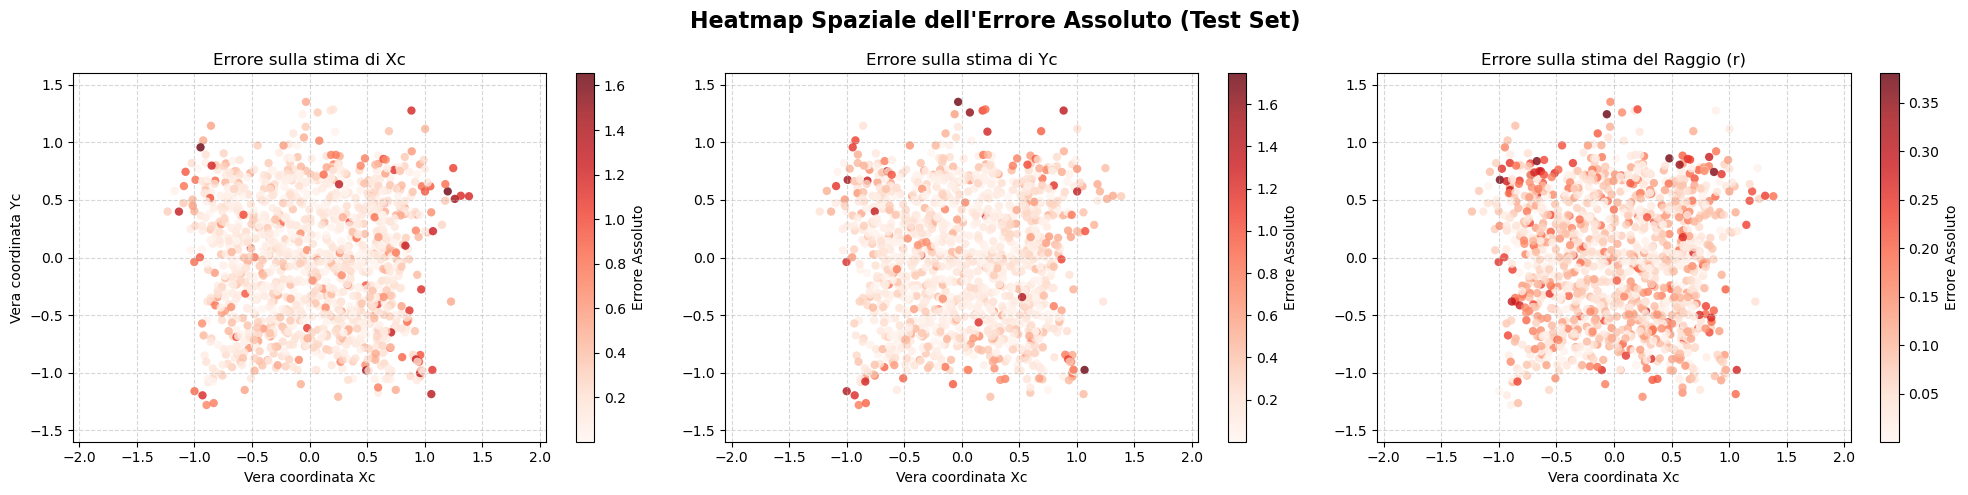

In [18]:
import matplotlib.pyplot as plt
import numpy as np

print("Esecuzione inferenza sul Test Set...")
# 1. Otteniamo le predizioni sul test set
y_pred_scaled = model.predict(X_test)

# 2. Denormalizziamo sia le predizioni che i target reali per avere errori in scale fisiche reali
y_pred_physical = scaler_y.inverse_transform(y_pred_scaled)
y_true_physical = scaler_y.inverse_transform(y_test_scaled)

# Assicuriamo il vincolo di positività sul raggio predetto
y_pred_physical[:, 2] = np.clip(y_pred_physical[:, 2], a_min=0.05, a_max=1.5)

# 3. Calcolo dell'Errore Assoluto per ogni variabile
err_xc = np.abs(y_true_physical[:, 0] - y_pred_physical[:, 0])
err_yc = np.abs(y_true_physical[:, 1] - y_pred_physical[:, 1])
err_r  = np.abs(y_true_physical[:, 2] - y_pred_physical[:, 2])

# Statistiche rapide
print(f"Errore Medio Assoluto (MAE) su Xc: {np.mean(err_xc):.3f}")
print(f"Errore Medio Assoluto (MAE) su Yc: {np.mean(err_yc):.3f}")
print(f"Errore Medio Assoluto (MAE) su Raggio: {np.mean(err_r):.3f}")

# 4. Creazione delle Heatmap Spaziali
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle("Heatmap Spaziale dell'Errore Assoluto (Test Set)", fontsize=16, fontweight='bold')

# Impostiamo le coordinate reali (X, Y) per posizionare i punti
X_true = y_true_physical[:, 0]
Y_true = y_true_physical[:, 1]

# Plot 1: Errore su Xc
# Usiamo cmap='Reds' per la mappa di calore (bianco=errore nullo, rosso scuro=errore alto)
sc1 = axes[0].scatter(X_true, Y_true, c=err_xc, cmap='Reds', alpha=0.8, edgecolors='none')
axes[0].set_title('Errore sulla stima di Xc')
axes[0].set_xlabel('Vera coordinata Xc')
axes[0].set_ylabel('Vera coordinata Yc')
axes[0].axis('equal')
plt.colorbar(sc1, ax=axes[0], label='Errore Assoluto')

# Plot 2: Errore su Yc
sc2 = axes[1].scatter(X_true, Y_true, c=err_yc, cmap='Reds', alpha=0.8, edgecolors='none')
axes[1].set_title('Errore sulla stima di Yc')
axes[1].set_xlabel('Vera coordinata Xc')
axes[1].axis('equal')
plt.colorbar(sc2, ax=axes[1], label='Errore Assoluto')

# Plot 3: Errore sul Raggio
sc3 = axes[2].scatter(X_true, Y_true, c=err_r, cmap='Reds', alpha=0.8, edgecolors='none')
axes[2].set_title('Errore sulla stima del Raggio (r)')
axes[2].set_xlabel('Vera coordinata Xc')
axes[2].axis('equal')
plt.colorbar(sc3, ax=axes[2], label='Errore Assoluto')

# Aggiunta di un reticolo per orientamento
for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    # Aggiungiamo i limiti approssimativi del dominio cardiaco [-1.5, 1.5]
    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)

plt.tight_layout()
plt.show()